# ANÁLISE P1 | _The Numbers Domestic Box Office Dataset_
___
Análises voltadas para responder a pergunta P1.
___

### 0 | Importações
___

In [2]:
# Manipulação de dados:
import pandas as pd
import numpy as np        

# Visualização de dados:
import plotly.express as px 
import plotly.io as pio

pio.renderers.default='png'

In [3]:
df = pd.read_csv('../data/processed/tabela_tratada.csv') # Importando o dataset

### P1 | Arrecadação na estreia vs. Legs como influência no box office:
___

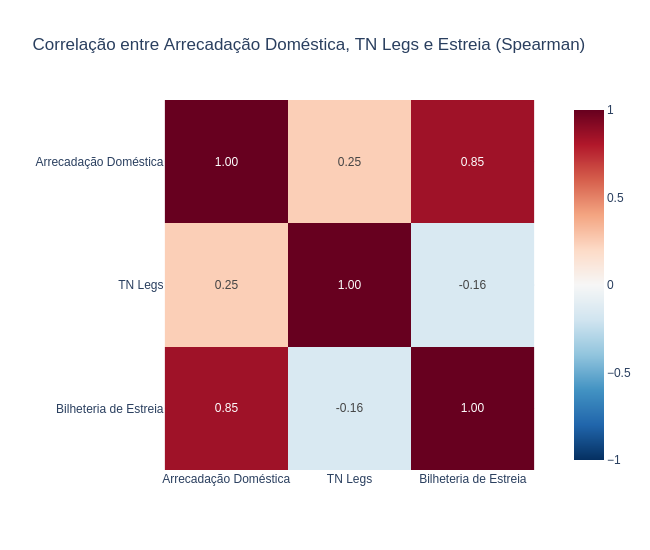

In [4]:
col_legs = 'tn_legs' if 'tn_legs' in df.columns else 'legs'
cols_foco = ['domestic_bo', col_legs, 'estreia_bilheteria']

corr_spearman = df[cols_foco].corr(method='spearman')
corr_pearson = df[cols_foco].corr(method='pearson')

# Escolha qual matriz plotar: 'spearman' (recomendada) ou 'pearson'
matriz = corr_spearman

# Rótulos amigáveis para os eixos
rotulos = {
    'domestic_bo': 'Arrecadação Doméstica',
    col_legs: 'TN Legs',
    'estreia_bilheteria': 'Bilheteria de Estreia'
}

matriz_plot = matriz.rename(index=rotulos, columns=rotulos)

# 3. Gera o Heatmap interativo com Plotly
fig = px.imshow(
    matriz_plot,
    text_auto='.2f',
    color_continuous_scale='RdBu_r',
    zmin=-1,
    zmax=1,
    title=f'Correlação entre Arrecadação Doméstica, TN Legs e Estreia (Spearman)'
)

fig.update_layout(
    width=650,
    height=550,
    template='plotly_white',
    xaxis_title='',
    yaxis_title=''
)

fig.show()

             qtd      mediana          q1           q3         media
faixa_legs                                                          
< 2          103   35792919.0  12552060.0   72911041.0  5.329002e+07
2 – 5       2261   81966078.0  50484906.0  151848346.0  1.283423e+08
5 – 10       265  102873175.0  47255180.0  201350044.0  1.464950e+08
> 10          65   74093778.0  54667629.0  132412724.0  1.226604e+08


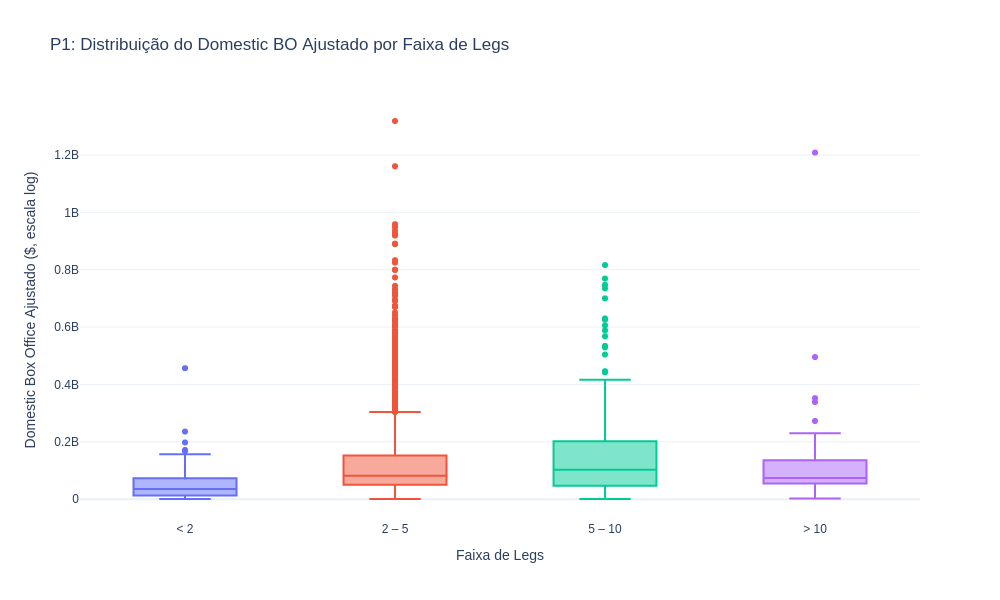

In [ ]:
col_legs = 'tn_legs' if 'tn_legs' in df.columns else 'legs'
if col_legs not in df.columns:
    df['tn_legs'] = np.where(
        df['estreia_bilheteria'] > 0,
        df['domestic_bo'] / df['estreia_bilheteria'],
        np.nan
    )
    col_legs = 'tn_legs'

# 2. Filtra valores válidos (domestic_bo > 0 e legs > 0)
base = df[
    (df['domestic_bo'] > 0) &
    (df[col_legs] > 0)
].dropna(subset=['domestic_bo', col_legs]).copy()

# 3. Cria as faixas solicitadas: <2, 2-5, 5-10, >10
bins = [0, 2, 5, 10, np.inf]
labels_legs = ['< 2', '2 – 5', '5 – 10', '> 10']

base['faixa_legs'] = pd.cut(
    base[col_legs],
    bins=bins,
    labels=labels_legs,
    include_lowest=True,
    right=False  # <2, [2,5), [5,10), >=10
)

base = base.dropna(subset=['faixa_legs'])

# Resumo numérico rápido por faixa (útil para apoiar o texto da P1)
resumo = (
    base.groupby('faixa_legs', observed=False)['domestic_bo']
    .agg(
        qtd='count',
        mediana='median',
        q1=lambda s: s.quantile(0.25),
        q3=lambda s: s.quantile(0.75),
        media='mean'
    )
    .round(2)
)
print(resumo)

# 4. Boxplot do Domestic BO ajustado por faixa de Legs
fig = px.box(
    base,
    x='faixa_legs',
    y='domestic_bo',
    color='faixa_legs',
    #log_y=True,
    points='outliers',
    category_orders={'faixa_legs': labels_legs},
    title='P1: Distribuição do Domestic BO Ajustado por Faixa de Legs',
    labels={
        'faixa_legs': 'Faixa de Legs',
        'domestic_bo': 'Domestic Box Office Ajustado ($)'
    }
)

# Ticks limpos no eixo Y em escala logarítmica
#fig.update_yaxes(
#    type='log',
#    tickvals=[1e5, 1e6, 1e7, 1e8, 1e9],
#    ticktext=['$100k', '$1M', '$10M', '$100M', '$1B']
#)

fig.update_layout(
    width=1000,
    height=600,
    template='plotly_white',
    showlegend=False
)

fig.show()

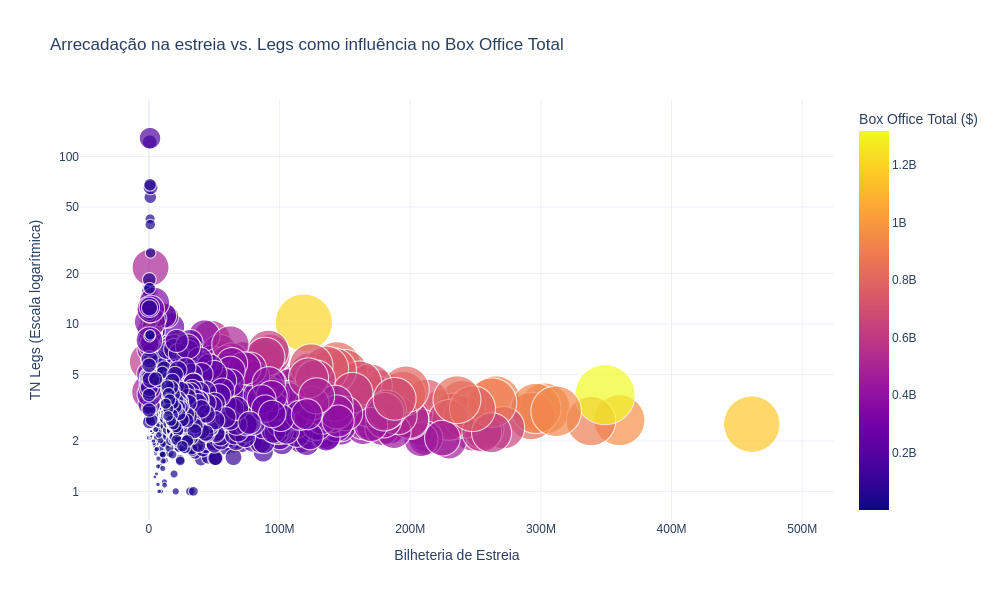

In [6]:
# Remove valores nulos nas três colunas essenciais
df_plot = df.dropna(subset=['estreia_bilheteria', 'tn_legs', 'domestic_bo']).copy()

# 2. Cria o Gráfico de Bolhas
fig = px.scatter(
    df_plot,
    x='estreia_bilheteria',
    y='tn_legs',
    size='domestic_bo',       # O TAMANHO da bolha é o Box Office Total (quanto maior, mais faturou)
    color='domestic_bo',      # A COR da bolha reforça o volume de faturamento
    hover_name='nome',
    hover_data=['year', 'genre', 'rating'],
    title='Arrecadação na estreia vs. Legs como influência no Box Office Total',
    labels={
        'estreia_bilheteria': 'Bilheteria de Estreia ($)',
        'tn_legs': 'TN Legs (Sustentabilidade / Consistência)',
        'domestic_bo': 'Box Office Total ($)'
    },
    color_continuous_scale='Plasma', # Escala de cores (tons mais claros/amarelos = maiores bilheterias)
    size_max=60                      # Limite máximo do tamanho da bolha para não embolar
)

# 3. Ajustes visuais (Escala log no eixo X por conta da disparidade dos blockbusters)
fig.update_layout(
    xaxis_title='Bilheteria de Estreia',
    yaxis_title='TN Legs (Escala logarítmica)',
    width=1000,
    height=600,
    template='plotly_white'
)

fig.update_yaxes(
    type='log',
    tickvals=[1, 2, 5, 10, 20, 50, 100],
    ticktext=['1', '2', '5', '10', '20', '50', '100']
)


# Exibe o gráfico interativo
fig.show()

O gráfico aparenta denunciar, em geral, a presena de um gradiente de cores da esquerda para a direita do gráfico. Isso indica que a bilheteria total está mais associada com a arrecadação na estreia do que com o valor de Legs de um filme, com o valor de legs das maiores estreias se concentrando em uma faixa entre 2 e 5.

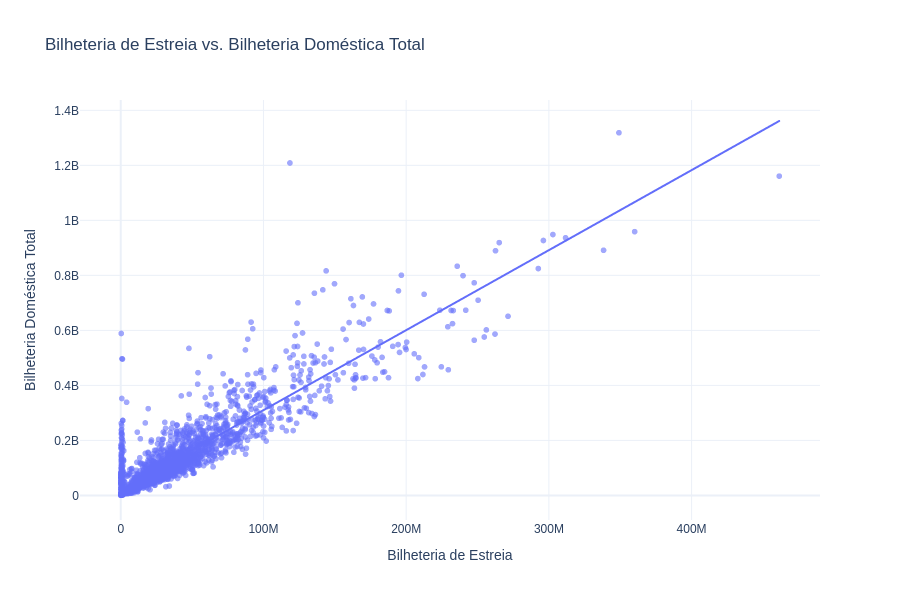

In [7]:
df_plot = df.dropna(subset=['estreia_bilheteria', 'domestic_bo']).copy()

# Cria o gráfico de dispersão
fig = px.scatter(
    df_plot,
    x='estreia_bilheteria',
    y='domestic_bo',
    hover_name='nome',
    #color='genre',
    hover_data=['year', 'genre', 'tn_legs'],
    trendline='ols',          # Linha de tendência estatística
    title='Bilheteria de Estreia vs. Bilheteria Doméstica Total',
    labels={
        'estreia_bilheteria': 'Bilheteria de Estreia ($)',
        'domestic_bo': 'Bilheteria Doméstica Total ($)'
    },
    opacity=0.6
)

# Ajustes vitais: Escala logarítmica em AMBOS os eixos para dados de bilheteria
fig.update_layout(
    #xaxis_type='log',
    #yaxis_type='log',
    xaxis_title='Bilheteria de Estreia',
    yaxis_title='Bilheteria Doméstica Total',
    width=900,
    height=600,
    template='plotly_white'
)

fig.show()

O gráfico acima parece confirmar a hipótese de uma relação linear entre arrecadação na estreia e bilheteria total.